In [17]:
# System Imports
import sys
sys.path.insert(0, "../src")
import codebookmap
import armpipelines

# project imports
from codebookmap import BRFSS_MAP
from armpipelines import make_arm_a
from armpipelines import make_arm_b

#pandas and numpy import
import pandas as pd
import numpy as np

# silence warnings
import warnings
warnings.filterwarnings('ignore')

# Pipeline and simple imputer imports
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

# Model and validation imports
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, auc, make_scorer, average_precision_score

from imblearn.over_sampling import SMOTE

In [2]:
dev = pd.read_parquet("../../data/dev.parquet")
dev.head()

,_STATE,_METSTAT,_URBSTAT,SEXVAR,_AGE80,_RACE,MARITAL,EDUCA,RENTHOM1,VETERAN3,...,HIVTST7,PNEUVAC4,TETANUS1,FRUIT2,FRUITJU2,FVGREEN1,FRENCHF1,POTATOE1,VEGETAB2,CLASS
0,33.0,2.0,2.0,2.0,54.0,1.0,1.0,6.0,1.0,1.0,...,2.0,1.0,1.0,203.0,203.0,203.0,555.0,301.0,202.0,1
1,39.0,1.0,1.0,1.0,59.0,1.0,1.0,4.0,1.0,1.0,...,1.0,1.0,1.0,203.0,204.0,202.0,203.0,306.0,203.0,1
2,19.0,1.0,1.0,1.0,74.0,1.0,1.0,4.0,1.0,1.0,...,2.0,2.0,3.0,310.0,555.0,101.0,300.0,300.0,101.0,1
3,36.0,1.0,1.0,2.0,46.0,2.0,1.0,6.0,1.0,2.0,...,1.0,2.0,4.0,102.0,555.0,101.0,201.0,101.0,101.0,0
4,47.0,2.0,1.0,1.0,63.0,1.0,2.0,5.0,1.0,1.0,...,2.0,2.0,NaN,201.0,201.0,102.0,102.0,555.0,101.0,0


In [3]:
summary_stats = dev['PHYSHLTH'].describe()
desc_with_na = summary_stats.append(pd.Series({
    'NaN_count': dev['PHYSHLTH'].isna().sum()
}))
print(desc_with_na)

count        50000.000000
mean            58.047120
std             37.810851
min              1.000000
25%             14.000000
50%             88.000000
75%             88.000000
max             99.000000
NaN_count        0.000000
dtype: float64


In [4]:
df_arm_b_X, df_arm_b_y = make_arm_b(dev)
df_arm_a_X, df_arm_a_y = make_arm_a(dev)

In [6]:
nominal_cols = [
        col
        for col, rules in BRFSS_MAP.items()
        if rules["type"] == "nominal" and not rules.get("is_target")
    ]
numeric_cols = [
        col
        for col, rules in BRFSS_MAP.items()
        if rules["type"] in ["ordinal", "continuous"] and not rules.get("is_target")
    ]

In [7]:
#Pipeline A
# Numeric branch (Arm A)
naive_numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean', add_indicator=False)),
    ('scaler', StandardScaler())
])

# Nominal branch (Arm A)
naive_nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# preprocessor (Arm A)
preprocessor_arm_a = ColumnTransformer(
    transformers=[
        ('num', naive_numeric_transformer, numeric_cols),
        ('cat', naive_nominal_transformer, nominal_cols)
    ]
)

In [8]:
#Pipeline B
#  Rule 1(Arm B) : One-Hot Encode (including 'Unknown')
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

#  Rule 2 (Arm B): Impute -> Missing Indicators -> Standardize
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

# preprocessor
preprocessor_arm_b = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', nominal_transformer, nominal_cols)
    ]
)

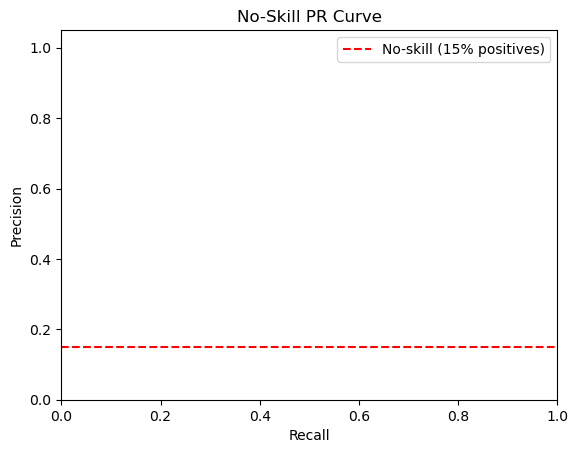

In [13]:
# 15% positives
actual_length = len(df_arm_b_y)
# No-skill model: constant probability 0.5
y_score = np.full(actual_length, 0.15)

precision, recall, thresholds = precision_recall_curve(df_arm_b_y, y_score)

# Plot
import matplotlib.pyplot as plt
# Draw a flat horizontal line at the 15% prevalence mark
plt.axhline(y=0.15, color='r', linestyle='--', label='No-skill (15% positives)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('No-Skill PR Curve')
plt.ylim([0.0, 1.05]) # Locks the Y-axis from 0 to 1 so the line sits near the bottom
plt.legend()
plt.show()

In [15]:
print(df_arm_b_y.mean())   # expect ~0.1513

0.1513


In [18]:
# Define StratifiedKFold
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

In [22]:
# Baseline Model(age, BMI, sex, hypertension, and physical activity)
baseline_values = ['_AGE80','_BMI5','SEXVAR','BPHIGH6','EXERANY2']
baseline_df_X = df_arm_b_X[baseline_values].copy()

def clean_nominal_values(X):
    X = X.copy()
    for col in X.columns:
        # Replace 'not sure', 'Refused' values to 'Unknown'
        X[col] = X[col].replace(['Not Sure', 'Refused'], 'Unknown')
    return X

cleaner = FunctionTransformer(clean_nominal_values)

# Baseline Transformer
basenominal_transformer = Pipeline(steps=[
    ('cleaner', cleaner),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

#  Rule 2 (Arm B): Impute -> Missing Indicators -> Standardize
basenumeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

# preprocessor
preprocessor_baseline = ColumnTransformer(
    transformers=[
        ('num', basenumeric_transformer, numeric_cols),
        ('cat', basenominal_transformer, nominal_cols)
    ]
)

# Full pipeline
baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor_baseline),
    ('classifier', LogisticRegression(solver='liblinear'))
])

# Define scorer for Average Precision
ap_scorer = make_scorer(average_precision_score, needs_proba=True)

# Run cross-validation
scores = cross_val_score(baseline_model, baseline_df_X, df_arm_b_y, cv=cv, scoring=ap_scorer)

ValueError: 
All the 10 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/kolawoleesther/anaconda3/lib/python3.10/site-packages/pandas/core/indexes/base.py", line 3802, in get_loc
    return self._engine.get_loc(casted_key)
  File "pandas/_libs/index.pyx", line 138, in pandas._libs.index.IndexEngine.get_loc
  File "pandas/_libs/index.pyx", line 165, in pandas._libs.index.IndexEngine.get_loc
  File "pandas/_libs/hashtable_class_helper.pxi", line 5745, in pandas._libs.hashtable.PyObjectHashTable.get_item
  File "pandas/_libs/hashtable_class_helper.pxi", line 5753, in pandas._libs.hashtable.PyObjectHashTable.get_item
KeyError: 'EDUCA'

The above exception was the direct cause of the following excepti